In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
listings = pd.read_csv('../02_Data/processed/listings_clean.csv', low_memory=False)

--- Advertised Nightly Price (€) ---


,Value
count,13355.00
mean,240.62
median,177.67
Min,3.50
P25,89.29
P50,177.67
P75,285.50
P90,413.00
P95,548.00
P99,1815.00


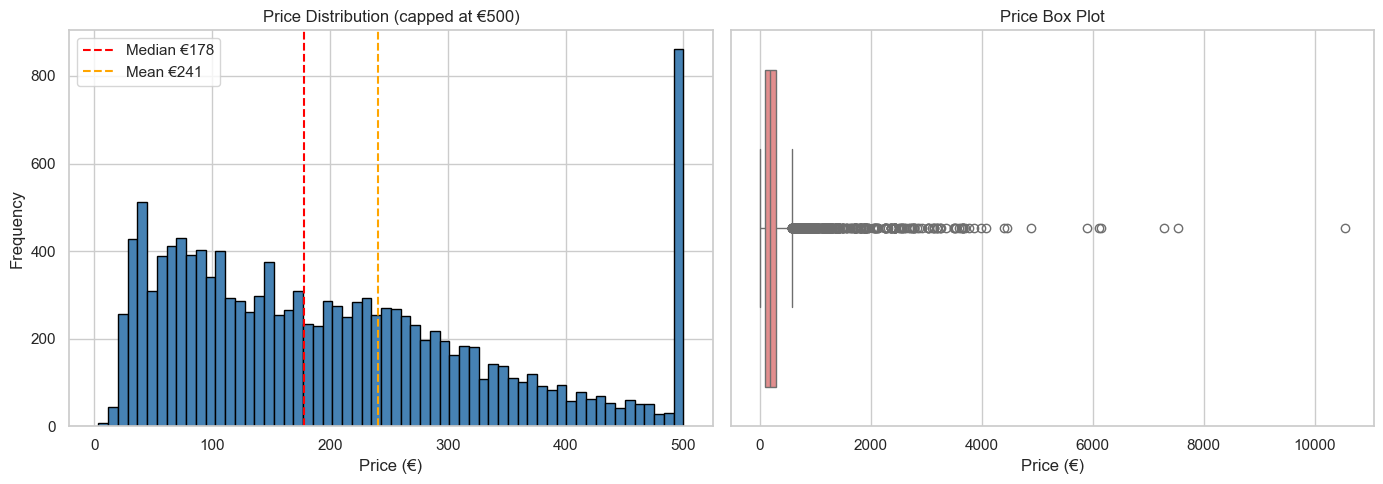

In [7]:
#  pricw distribution

prices = listings["price"].dropna()

stats = pd.Series({
    'count' : len(prices),
    'mean' : prices.mean(),
    'median' : prices.median(),
    'Min': prices.min(),
    'P25' : prices.quantile(0.25),
    'P50': prices.quantile(0.50),
    'P75': prices.quantile(0.75),
    'P90': prices.quantile(0.90),
    'P95': prices.quantile(0.95),
    'P99': prices.quantile(0.99),
    'Max': prices.max(),
    'Skewness': prices.skew(),
}).round(2)

print("--- Advertised Nightly Price (€) ---")
display(stats.to_frame('Value'))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].hist(prices.clip(upper=500), bins=60, color = 'steelblue', edgecolor='black')
ax[0].set_title('Price Distribution (capped at €500)')
ax[0].set_xlabel('Price (€)')
ax[0].set_ylabel('Frequency')
ax[0].axvline(prices.median(), color='red', ls='--', label=f'Median €{prices.median():.0f}')
ax[0].axvline(prices.mean(), color='orange', ls='--', label=f'Mean €{prices.mean():.0f}')
ax[0].legend()

sns.boxplot(x= prices, ax=ax[1], color='lightcoral')
ax[1].set_title('Price Box Plot')
ax[1].set_xlabel('Price (€)')

plt.tight_layout()
plt.show()

In [12]:
# IQR method

q1, q3 = prices.quantile([0.25,0.75])
iqr = q3-q1
upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr

print(f"IQR: €{iqr:.0f}")
print(f"Upper fence: €{upper_fence:.0f}")
print(f"Lower fence: €{lower_fence:.0f}")

outliers = listings[listings['price']> upper_fence]
print(f'Outliers above upper fence: {len(outliers):,} ({len(outliers)/len(listings)*100:.1f}%)')

#  high price
cols_to_check = ['id','name','neighbourhood','room_type','accommodates','bedrooms','price','minimum_nights']
print("\n--- Top 10 Most Expensive Listings ---")
display(outliers.nlargest(10, 'price')[cols_to_check])

IQR: €196
Upper fence: €580
Lower fence: €-205
Outliers above upper fence: 586 (3.8%)

--- Top 10 Most Expensive Listings ---


,id,name,neighbourhood,room_type,accommodates,bedrooms,price,minimum_nights
8077,867256504774715226,Amazing loft-style apartment in Las Ramblas,el Barri Gòtic,Entire home/apt,2,1.0,10542.22,32.0
12321,1426637760045243370,Elegant 12-bedr GroupFlat with 12-bathr 24 people,la Dreta de l'Eixample,Entire home/apt,16,12.0,7532.00,1.0
12139,1405062163700981309,Elegant 12-bedr GroupFlat with 12-bathr 24 people,la Dreta de l'Eixample,Entire home/apt,16,12.0,7293.00,1.0
12155,1406454143054865483,Acomodis • Groups • Up to 27 Guests • Ask for ...,la Dreta de l'Eixample,Entire home/apt,16,14.0,6151.00,1.0
12112,1400057633003120901,GroupFlat 15-Bedr 10-Bath next Casa Batlló 35 ppl,la Dreta de l'Eixample,Entire home/apt,16,15.0,6106.00,1.0
10137,1157205495486273795,Just 10 minutes from Casa Batlló Gaudi - 22 pe...,la Dreta de l'Eixample,Entire home/apt,16,10.0,5900.00,1.0
11240,1309611159285218484,GroupFlat 12-Bed 8-Bath next Casa Batlló 28people,la Dreta de l'Eixample,Entire home/apt,16,12.0,4885.00,1.0
8356,909087702399642381,Modern Apartment With Balcony In Lively Area,la Nova Esquerra de l'Eixample,Entire home/apt,4,2.0,4463.00,1.0
11224,1308738273720498469,Great GroupFlat 15-bed 10-bath Eixample 30 ppl!,la Nova Esquerra de l'Eixample,Entire home/apt,16,15.0,4394.00,1.0
12859,1473123174977324233,Nice 15-Bedroom 10-Bath near Pl. Catalunya 30 ppl,"Sant Pere, Santa Caterina i la Ribera",Entire home/apt,16,15.0,4080.00,1.0
